##MINI EDA: PALMER PENGUINS

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

##1.LOAD DATA

In [3]:
df = pd.read_csv(r"C:\Users\khond\OneDrive\Desktop\Python Internship Task\Active_Employees.csv", encoding="latin1")
print("Shape:", df.shape)
display(df.head())

Shape: (800, 14)


,Employee_ID,Employee_Name,Gender,Age,Department,Job_Title,City,State,Joining_Date,Salary,Performance_Score,Bonus,Employment_Status,Grade
0,10001,Pooja Deshmukh,Female,27,Sales,Sales Executive,Pune,Maharashtra,2024-10-17 00:00:00,45000,97,6167.77,Active,D
1,10010,Kavya Deshmukh,Female,53,HR,HR Executive,Ahmedabad,Gujarat,2023-10-08 00:00:00,55000,55,6638.16,Active,B
2,10013,Neha More,Female,40,IT,Software Developer,Aurangabad,Maharashtra,2025-09-20 00:00:00,93000,90,8455.52,Active,B
3,10016,Meera Kadam,Male,54,Operations,Operations Executive,Mumbai,Maharashtra,2025-11-22 00:00:00,60000,88,4846.59,Active,B
4,10017,Karan More,Male,28,HR,HR Executive,Aurangabad,Maharashtra,2022-05-23 00:00:00,53000,64,1997.20,Active,B


##Step 2: Data cha first look (pahila nirikshan)
Cell 1: Columns ani data types

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Employee_ID        800 non-null    int64  
 1   Employee_Name      800 non-null    str    
 2   Gender             800 non-null    str    
 3   Age                800 non-null    int64  
 4   Department         800 non-null    str    
 5   Job_Title          800 non-null    str    
 6   City               800 non-null    str    
 7   State              800 non-null    str    
 8   Joining_Date       800 non-null    str    
 9   Salary             800 non-null    int64  
 10  Performance_Score  800 non-null    int64  
 11  Bonus              800 non-null    float64
 12  Employment_Status  800 non-null    str    
 13  Grade              800 non-null    str    
dtypes: float64(1), int64(4), str(9)
memory usage: 87.6 KB


##Step 2 (purna karaycha): 3 lahan cells
Cell 1: Duplicate rows
Arth: Kiti rows doni veli aahet, ani kiti Employee_ID repeat zalele aahet te baghto.

In [5]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate Employee_ID:", df["Employee_ID"].duplicated().sum())

Duplicate rows: 0
Duplicate Employee_ID: 0


##Cell 2: Text columns madhe kay values aahet
Arth: Pratyek column madhe konkonti vegvegli values aahet te dakhavto. Tyatun male / Male / M sarkhi chuk disel.

In [6]:
for col in ["Gender", "Department", "State", "Employment_Status", "Grade"]:
    print(col, ":", df[col].unique())

Gender : <StringArray>
['Female', 'Male']
Length: 2, dtype: str
Department : <StringArray>
['Sales', 'HR', 'IT', 'Operations', 'Marketing', 'Finance',
 'Customer Support']
Length: 7, dtype: str
State : <StringArray>
['Maharashtra', 'Gujarat', 'Delhi', 'Karnataka', 'Madhya Pradesh',
 'Telangana']
Length: 6, dtype: str
Employment_Status : <StringArray>
['Active']
Length: 1, dtype: str
Grade : <StringArray>
['D', 'B', 'C', 'A']
Length: 4, dtype: str


##Cell 3: Numbers madhe kahi chukiche values aahet ka
Arth: Age, Salary, Bonus cha min ani max dakhavto. Age 0 kinva 150 asel, kinva Salary negative asel, tar chuk aahe.

In [7]:
df.describe()

,Employee_ID,Age,Salary,Performance_Score,Bonus
count,800.000000,800.000000,800.000000,800.000000,800.000000
mean,11248.571250,37.693750,54063.750000,73.925000,4885.632725
std,707.803652,10.384713,15399.468025,14.447155,2277.601571
min,10001.000000,21.000000,25000.000000,50.000000,1012.990000
25%,10684.500000,28.000000,43000.000000,61.000000,3168.587500
50%,11276.000000,37.000000,53000.000000,73.000000,4561.590000
75%,11834.000000,47.000000,64000.000000,86.000000,6313.610000
max,12500.000000,55.000000,95000.000000,100.000000,13599.890000


##Step 3: Cleaning (lahan cells madhe)
Cell 1: Copy banva

In [8]:
df_clean = df.copy()

##Cell 2: Joining_Date la date madhe badla

In [9]:
df_clean["Joining_Date"] = pd.to_datetime(df_clean["Joining_Date"])
df_clean["Joining_Year"] = df_clean["Joining_Date"].dt.year
print(df_clean["Joining_Date"].dtype)

datetime64[us]


##Cell 3: Text swachh kara

In [10]:
text_cols = ["Employee_Name", "Gender", "Department", "Job_Title",
             "City", "State", "Employment_Status", "Grade"]

for col in text_cols:
    df_clean[col] = df_clean[col].str.strip()

##Cell 4: Duplicates kadha

In [11]:
before = len(df_clean)
df_clean = df_clean.drop_duplicates()
df_clean = df_clean.drop_duplicates(subset="Employee_ID")
print("Removed:", before - len(df_clean), "duplicate rows")

Removed: 0 duplicate rows


##Cell 5: Category values ek sarkhya aahet ka tapasa

In [13]:
for col in ["Gender", "Department", "State", "Grade", "Employment_Status"]:
    print(col, ":", df_clean[col].unique())

Gender : <StringArray>
['Female', 'Male']
Length: 2, dtype: str
Department : <StringArray>
['Sales', 'HR', 'IT', 'Operations', 'Marketing', 'Finance',
 'Customer Support']
Length: 7, dtype: str
State : <StringArray>
['Maharashtra', 'Gujarat', 'Delhi', 'Karnataka', 'Madhya Pradesh',
 'Telangana']
Length: 6, dtype: str
Grade : <StringArray>
['D', 'B', 'C', 'A']
Length: 4, dtype: str
Employment_Status : <StringArray>
['Active']
Length: 1, dtype: str


##Cell 6: Outliers cha count

In [14]:
num_cols = ["Age", "Salary", "Performance_Score", "Bonus"]
for col in num_cols:
    Q1, Q3 = df_clean[col].quantile([0.25, 0.75])
    IQR = Q3 - Q1
    n = ((df_clean[col] < Q1 - 1.5*IQR) | (df_clean[col] > Q3 + 1.5*IQR)).sum()
    print(col, ":", n, "outliers")

Age : 0 outliers
Salary : 0 outliers
Performance_Score : 0 outliers
Bonus : 8 outliers


##Cell 7: Shevtche check

In [15]:
print("Final shape:", df_clean.shape)
print("Missing values:", df_clean.isnull().sum().sum())
df_clean.dtypes

Final shape: (800, 15)
Missing values: 0


Employee_ID                   int64
Employee_Name                   str
Gender                          str
Age                           int64
Department                      str
Job_Title                       str
City                            str
State                           str
Joining_Date         datetime64[us]
Salary                        int64
Performance_Score             int64
Bonus                       float64
Employment_Status               str
Grade                           str
Joining_Year                  int32
dtype: object

##Chart 1: Salary cha distribution (histogram)

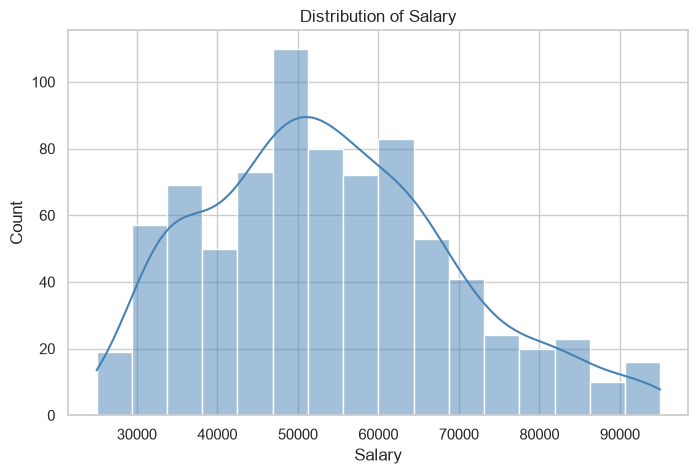

In [16]:
plt.figure(figsize=(8, 5))
sns.histplot(df_clean["Salary"], kde=True, color="steelblue")
plt.title("Distribution of Salary")
plt.xlabel("Salary")
plt.show()

##Chart 2: Department pramane employees (countplot)

C:\Users\khond\AppData\Local\Temp\ipykernel_804\1063783086.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_clean, x="Department", order=order, palette="viridis")


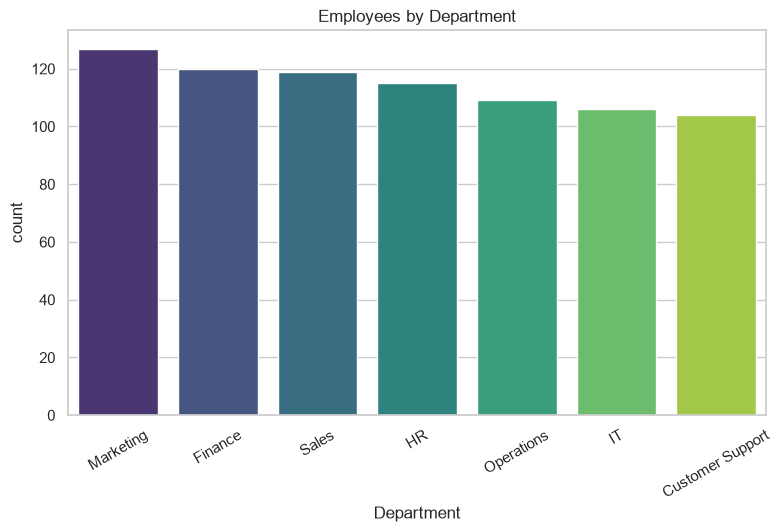

In [17]:
plt.figure(figsize=(9, 5))
order = df_clean["Department"].value_counts().index
sns.countplot(data=df_clean, x="Department", order=order, palette="viridis")
plt.title("Employees by Department")
plt.xticks(rotation=30)
plt.show()

##Chart 3: Department pramane Salary (boxplot)

C:\Users\khond\AppData\Local\Temp\ipykernel_804\454953361.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x="Department", y="Salary", palette="Set2")


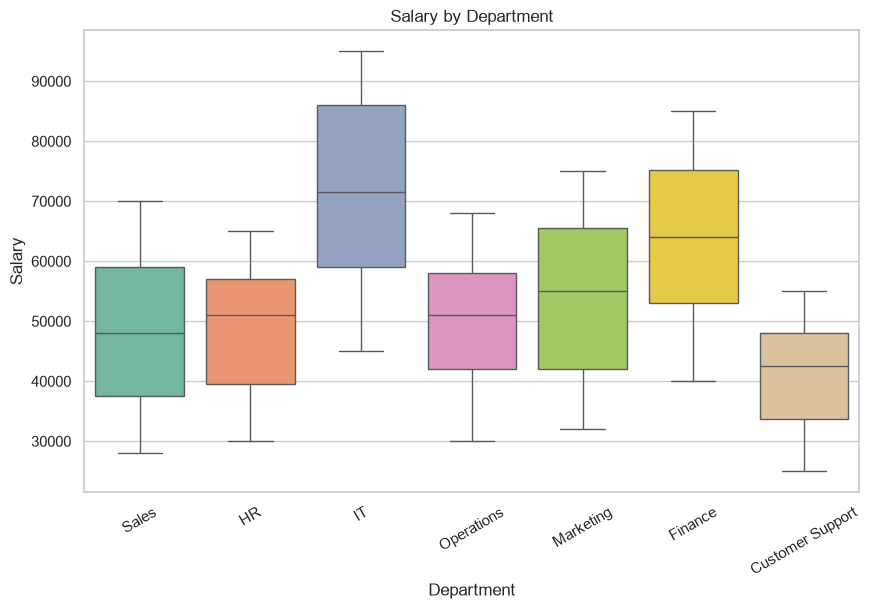

In [18]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_clean, x="Department", y="Salary", palette="Set2")
plt.title("Salary by Department")
plt.xticks(rotation=30)
plt.show()

##Chart 4: Correlation heatmap

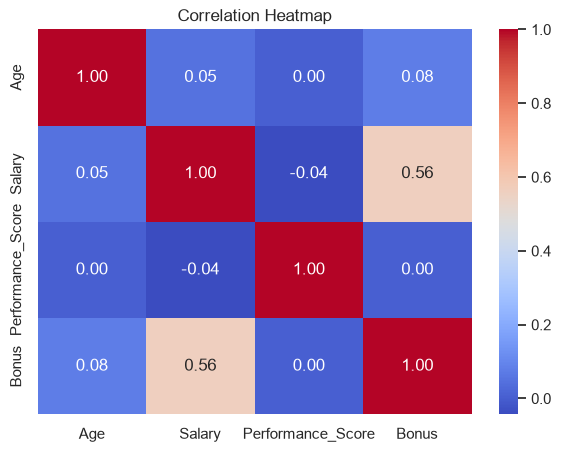

In [19]:
plt.figure(figsize=(7, 5))
sns.heatmap(df_clean[["Age", "Salary", "Performance_Score", "Bonus"]].corr(),
            annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

##Bonus chart (optional)

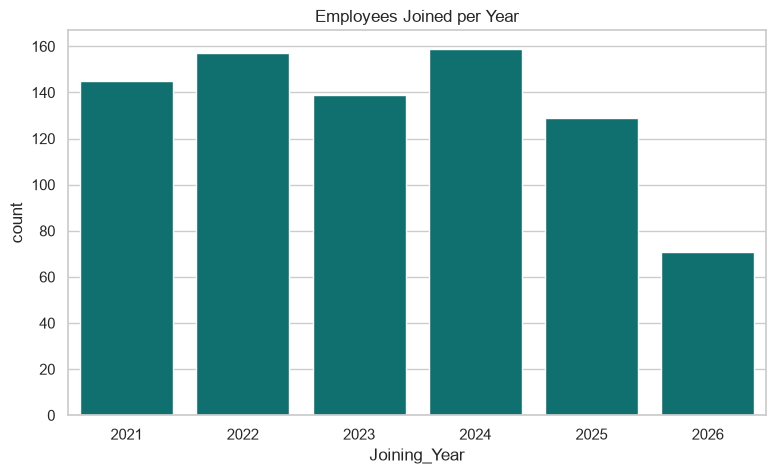

In [20]:
plt.figure(figsize=(9, 5))
sns.countplot(data=df_clean, x="Joining_Year", color="teal")
plt.title("Employees Joined per Year")
plt.show()

##Step 6: Insights ani Conclusion (shevtcha step)

In [22]:
# 1. Sarvat jast employees konatya department madhe
top_dept = df_clean["Department"].value_counts()
print("Sarvat jast employees:", top_dept.index[0], "(", top_dept.iloc[0], ")")

# 2. Sarvat jast ani sarvat kami salary department
dept_sal = df_clean.groupby("Department")["Salary"].mean().round(0).sort_values(ascending=False)
print("Sarvat jast avg salary:", dept_sal.index[0], "-", dept_sal.iloc[0])
print("Sarvat kami avg salary:", dept_sal.index[-1], "-", dept_sal.iloc[-1])

# 3. Gender pramane avg salary
print("\nGender pramane avg salary:")
print(df_clean.groupby("Gender")["Salary"].mean().round(0))

# 4. Grade pramane avg salary
print("\nGrade pramane avg salary:")
print(df_clean.groupby("Grade")["Salary"].mean().round(0))

# 5. Sarvat strong correlation
corr = df_clean[["Age", "Salary", "Performance_Score", "Bonus"]].corr().abs()
corr = corr.where(~np.eye(len(corr), dtype=bool))   # diagonal (swatashi swatacha) kadhla
a, b = corr.stack().idxmax()
print("Sarvat strong correlation:", a, "ani", b, "=", round(df_clean[a].corr(df_clean[b]), 2))

# 6. Konatya varshi sarvat jast jan join zale
print("Sarvat jast joining year:", df_clean["Joining_Year"].value_counts().idxmax())

Sarvat jast employees: Marketing ( 127 )
Sarvat jast avg salary: IT - 71858.0
Sarvat kami avg salary: Customer Support - 41231.0

Gender pramane avg salary:
Gender
Female    54403.0
Male      53690.0
Name: Salary, dtype: float64

Grade pramane avg salary:
Grade
A    52412.0
B    53335.0
C    57503.0
D    53247.0
Name: Salary, dtype: float64
Sarvat strong correlation: Salary ani Bonus = 0.56
Sarvat jast joining year: 2024
